In [136]:
import os

import torch
import torch.nn as nn
import torch.nn.functional as F

from Uno.games_data.dataHandler import encode_data, prepare_data_for_learning

In [137]:
device = torch.device("cpu")
print(torch.cuda.is_available())
print(device)

False
cpu


In [138]:
os.chdir("/mnt/xD/Projekty/Python/NewUnoGame/UnoGame")
print(os.getcwd())

/mnt/xD/Projekty/Python/NewUnoGame/UnoGame


In [139]:
class Model(nn.Module):
    def __init__(self, in_features=16, h1=100, h2=100, out_features=60, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.fc1 = nn.Linear(in_features, h1)
        self.fc2 = nn.Linear(h1, h2)
        self.out = nn.Linear(h2, out_features)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.out(x)

        return x

In [140]:
#torch.manual_seed(41)
model = Model()

In [141]:
import pandas as pd

#df1 = pd.read_csv('Uno/games_data/MergedCSV/20240810_0951_uno_game.csv')
#df2 = pd.read_csv('Uno/games_data/MergedCSV/merged.csv')
df = pd.read_csv('Uno/games_data/MergedCSV/20241215_1909_uno_game.csv')
#df = pd.concat([df1, df3])
df = prepare_data_for_learning(df)
#df = df['is_game_over'].replace({True: 1, False: 0})
df['is_game_over'] = df['is_game_over'].astype('int')



In [142]:
df = df.loc[(df["card_played"] != "Draw")]
df = df.loc[df["card_played"] != "All Colors"]
df = df.loc[df["card_played"] != "+4 Colors"]
all_cards = df["card_played"].value_counts()

In [143]:
all_cards

card_played
+2 Yellow         12915
+2 Green          12773
+2 Red            12556
Stop Yellow       12544
Stop Green        12325
Stop Red          12307
+2 Blue           12272
Stop Blue         12224
9 Yellow          11918
7 Yellow          11862
2 Red             11837
8 Yellow          11806
1 Yellow          11787
3 Yellow          11783
6 Yellow          11756
8 Red             11754
6 Red             11752
Reverse Green     11746
3 Red             11741
8 Blue            11741
2 Yellow          11727
7 Red             11724
Reverse Blue      11723
6 Green           11710
2 Green           11696
4 Yellow          11676
7 Blue            11672
4 Red             11671
Reverse Yellow    11651
1 Blue            11650
Reverse Red       11638
5 Yellow          11619
3 Green           11616
5 Blue            11607
5 Green           11596
8 Green           11594
4 Blue            11571
4 Green           11570
7 Green           11560
9 Green           11555
5 Red             11546
1 Re

In [144]:
all_cards.iloc[-1]

1963

In [145]:
new_data_list = []
for card in all_cards.index.to_list():
    new_data = df.loc[df["card_played"] == card].iloc[:all_cards.iloc[-1]]
    new_data_list.append(new_data)
df = pd.concat(new_data_list, ignore_index=True)

In [146]:
df['card_played'].value_counts()

card_played
+2 Yellow         1963
+2 Green          1963
+2 Red            1963
Stop Yellow       1963
Stop Green        1963
Stop Red          1963
+2 Blue           1963
Stop Blue         1963
9 Yellow          1963
7 Yellow          1963
2 Red             1963
8 Yellow          1963
1 Yellow          1963
3 Yellow          1963
6 Yellow          1963
8 Red             1963
6 Red             1963
Reverse Green     1963
3 Red             1963
8 Blue            1963
2 Yellow          1963
7 Red             1963
Reverse Blue      1963
6 Green           1963
2 Green           1963
4 Yellow          1963
7 Blue            1963
4 Red             1963
Reverse Yellow    1963
1 Blue            1963
Reverse Red       1963
5 Yellow          1963
3 Green           1963
5 Blue            1963
5 Green           1963
8 Green           1963
4 Blue            1963
4 Green           1963
7 Green           1963
9 Green           1963
5 Red             1963
1 Red             1963
1 Green           1963

In [147]:
df, labels = encode_data(df)
df.head()

,num_red,num_green,num_blue,num_yellow,num_stop,num_plus2,num_plus4,top_card,num_cards_left_in_deck,round,num_enemy_cards,direction,num_colors_in_hand,num_cards_in_hand,is_game_over,index_of_a_player,card_played
0,1,0,2,2,1,2,0,44,0,0,4,0,1,4,0,0,0
1,0,0,0,1,0,1,0,35,36,63,2,1,2,6,1,1,0
2,2,1,0,1,0,1,0,14,16,7,1,1,1,0,0,0,0
3,0,0,0,3,1,1,0,6,13,28,1,0,2,1,0,1,0
4,2,0,2,3,0,1,0,48,0,0,4,0,1,4,0,0,0


In [148]:
df.shape

(117780, 17)

In [149]:
X = df.drop('card_played', axis=1)
y = df["card_played"]

In [150]:
X.columns

Index(['num_red', 'num_green', 'num_blue', 'num_yellow', 'num_stop',
       'num_plus2', 'num_plus4', 'top_card', 'num_cards_left_in_deck', 'round',
       'num_enemy_cards', 'direction', 'num_colors_in_hand',
       'num_cards_in_hand', 'is_game_over', 'index_of_a_player'],
      dtype='object')

In [151]:
from sklearn.model_selection import train_test_split

In [152]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=41)

In [153]:
X_train = torch.FloatTensor(X_train.to_numpy())
X_test = torch.FloatTensor(X_test.to_numpy())

In [154]:
y_train = torch.LongTensor(y_train.to_numpy())
y_test = torch.LongTensor(y_test.to_numpy())

In [155]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [156]:
model.parameters


<bound method Module.parameters of Model(
  (fc1): Linear(in_features=16, out_features=100, bias=True)
  (fc2): Linear(in_features=100, out_features=100, bias=True)
  (out): Linear(in_features=100, out_features=60, bias=True)
)>

In [157]:
epochs = 600
losses = []
print(y_train.min(), y_train.max())
for i in range(epochs):
    y_pred = model.forward(X_train)
    loss = criterion(y_pred, y_train)
    losses.append(loss.detach().numpy())

    if i % 10 == 0:
        print("Iteration {} \nLoss: {}".format(i, loss.detach().numpy()))


    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

tensor(0) tensor(59)
Iteration 0 
Loss: 4.654365062713623
Iteration 10 
Loss: 4.041194915771484
Iteration 20 
Loss: 3.922891855239868
Iteration 30 
Loss: 3.731438159942627
Iteration 40 
Loss: 3.5407888889312744
Iteration 50 
Loss: 3.3965718746185303
Iteration 60 
Loss: 3.2907779216766357
Iteration 70 
Loss: 3.2081947326660156
Iteration 80 
Loss: 3.1538264751434326
Iteration 90 
Loss: 3.0910122394561768
Iteration 100 
Loss: 3.0299088954925537
Iteration 110 
Loss: 2.990140199661255
Iteration 120 
Loss: 2.9478297233581543
Iteration 130 
Loss: 2.92380690574646
Iteration 140 
Loss: 2.9063634872436523
Iteration 150 
Loss: 2.8799679279327393
Iteration 160 
Loss: 2.861515522003174
Iteration 170 
Loss: 2.8534700870513916
Iteration 180 
Loss: 2.837671995162964
Iteration 190 
Loss: 2.825456380844116
Iteration 200 
Loss: 2.81062650680542
Iteration 210 
Loss: 2.801711320877075
Iteration 220 
Loss: 2.7940523624420166
Iteration 230 
Loss: 2.7990739345550537
Iteration 240 
Loss: 2.797178030014038
Iter

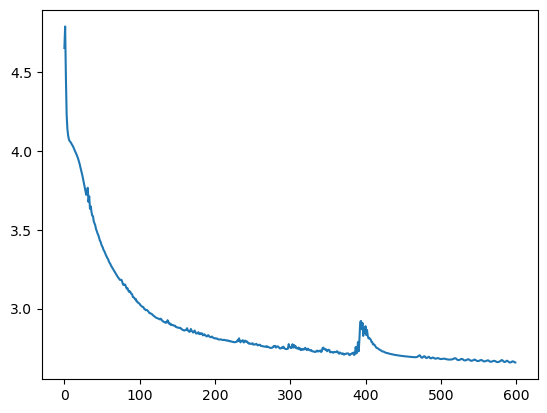

In [158]:
import matplotlib.pyplot as plt
plt.plot(losses)

In [159]:
# Evaluating model
with torch.no_grad(): # turns off back propagation
    y_pred = model.forward(X_test)
    loss = criterion(y_pred, y_test)

In [160]:
correct = 0
with torch.no_grad():
    for i, data in enumerate(X_test[:]):
        y_pred = model.forward(data)
        predicted_card = labels["card_played"][y_pred.argmax().item()]
        if y_pred.argmax().item() == y_test[i]:
            correct += 1
        #print(f"{predicted_card}, \t {labels["card_played"][int(y_test[i])]}")

correct

4813

In [161]:
print(f"Accuracy: {round(correct / X_test.shape[0], 2)}")

Accuracy: 0.2


In [162]:
labels["card_played"]

{0: '+2 Yellow',
 1: '+2 Green',
 2: '+2 Red',
 3: 'Stop Yellow',
 4: 'Stop Green',
 5: 'Stop Red',
 6: '+2 Blue',
 7: 'Stop Blue',
 8: '9 Yellow',
 9: '7 Yellow',
 10: '2 Red',
 11: '8 Yellow',
 12: '1 Yellow',
 13: '3 Yellow',
 14: '6 Yellow',
 15: '8 Red',
 16: '6 Red',
 17: 'Reverse Green',
 18: '3 Red',
 19: '8 Blue',
 20: '2 Yellow',
 21: '7 Red',
 22: 'Reverse Blue',
 23: '6 Green',
 24: '2 Green',
 25: '4 Yellow',
 26: '7 Blue',
 27: '4 Red',
 28: 'Reverse Yellow',
 29: '1 Blue',
 30: 'Reverse Red',
 31: '5 Yellow',
 32: '3 Green',
 33: '5 Blue',
 34: '5 Green',
 35: '8 Green',
 36: '4 Blue',
 37: '4 Green',
 38: '7 Green',
 39: '9 Green',
 40: '5 Red',
 41: '1 Red',
 42: '1 Green',
 43: '9 Blue',
 44: '6 Blue',
 45: '9 Red',
 46: '3 Blue',
 47: '2 Blue',
 48: '+4 Blue',
 49: 'All Blue',
 50: '0 Red',
 51: '0 Yellow',
 52: '0 Blue',
 53: '0 Green',
 54: 'All Green',
 55: '+4 Green',
 56: 'All Red',
 57: '+4 Red',
 58: '+4 Yellow',
 59: 'All Yellow'}

In [163]:
class ModelWithLabels:
    def __init__(self, model, labels):
        self.model = model
        self.labels = labels

    def get_model(self):
        return self.model

    def get_labels(self):
        return self.labels


In [164]:
import pickle
import datetime
def save_pickle(model, filename, is_temporary=False, directory=""):
    if is_temporary:
        filename = "tmp/" + filename
    else:
        filename = f"{datetime.datetime.now().strftime('%Y%m%d_%H%M')}_" + filename
    filename = directory + "/" + filename
    with open(filename, 'wb') as f:
        pickle.dump(model, f)
    return filename

In [170]:
model_with_labels = ModelWithLabels(model=model, labels=labels)

f_name = save_pickle(model_with_labels, f"epch{epochs}_1hid100_2hid100_dsize{y_train.shape[0]}", directory="Uno/NeuralNetwork/models")


In [166]:
import pickle
import os
def load_pickle(filename):
    abs_path = os.path.abspath(filename)
    with open(abs_path, 'rb') as f:
        return pickle.load(f)

In [167]:
#model = load_pickle("Uno/NeuralNetwork/models/20241215_0218_epch3000_1hid100_2hid100")

In [168]:
import numpy as np


with torch.no_grad():
    y_pred = model.get_model().forward(data)
    y_pred_numpy = y_pred.detach().numpy()

    indices = np.arange(y_pred_numpy.size)

    array_2d = np.column_stack([indices, y_pred_numpy])
    array_2d = array_2d[array_2d[:, 1].argsort()][-1:0:-1]

    print(array_2d)




AttributeError: 'Model' object has no attribute 'get_model'